# Weighted Soft Voting Ensemble — Five Media-Bias Classifiers

This notebook implements **only weighted soft voting** for:
1. TF-IDF + Linear SVM
2. TF-IDF + Logistic Regression
3. TF-IDF + Multinomial Naive Bayes
4. RoBERTa
5. DeBERTa

## Important experimental rules
- All five models must use the **same saved BABE train/validation/test split** and the same label mapping (`0 = Non-biased`, `1 = Biased`).
- Weights are selected using **validation macro-F1 only**. The test set is used only for the final evaluation.
- Do not mix the paper's 527-sample article-disjoint results with the newer 508-sample split. This notebook uses `babe_sg2_splits`.
- Transformer checkpoints must have been trained on the same training split. If a checkpoint was trained on a different split, do not include it in this comparison.
- This notebook does not assume the ensemble will beat DeBERTa; it measures that empirically.

Run in Google Colab with a GPU runtime recommended for transformer inference.


## 1. Install dependencies

In [ ]:
%pip -q install transformers accelerate scikit-learn pandas numpy matplotlib joblib


## 2. Mount Drive and configure paths

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import ParameterGrid
import joblib

SEED = 42
SPLIT_DIR = Path("/content/drive/MyDrive/NewsBias_Project_Backup/babe_sg2_splits")
OUTPUT_DIR = Path("/content/drive/MyDrive/NewsBias_Project_Backup/weighted_soft_voting")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Split directory exists:", SPLIT_DIR.exists())
print("RoBERTa checkpoint exists:", ROBERTA_DIR.exists())
print("DeBERTa checkpoint exists:", DEBERTA_DIR.exists())
print("Output directory:", OUTPUT_DIR)


Mounted at /content/drive
Split directory exists: True
RoBERTa checkpoint exists: False
DeBERTa checkpoint exists: True
Output directory: /content/drive/MyDrive/NewsBias_Project_Backup/weighted_soft_voting


In [ ]:

from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification

ROBERTA_DIR = Path(
    "/content/drive/MyDrive/NewsBias_Project_Backup/"
    "newsbias_roberta_best_retrained/best_model"
)

DEBERTA_DIR = Path(
    "/content/drive/MyDrive/NewsBias_Project_Backup/"
    "deberta_augmented_experiment/babe_only/best_model"
)

# Tokenizers from the original base-model repositories.
ROBERTA_TOKENIZER_NAME = "FacebookAI/roberta-base"

# IMPORTANT:
# Confirm the exact DeBERTa base model used during training before
# using this identifier. The checkpoint's model_type is "deberta-v2".
# If your training notebook specifies a different base model, use that.
DEBERTA_TOKENIZER_NAME = "microsoft/deberta-v3-base"

# Load the original tokenizers separately from the fine-tuned weights.
roberta_tokenizer = AutoTokenizer.from_pretrained(
    ROBERTA_TOKENIZER_NAME,
    use_fast=False
)

deberta_tokenizer = AutoTokenizer.from_pretrained(
    DEBERTA_TOKENIZER_NAME,
    use_fast=False
)

# Load the fine-tuned classification models from your saved checkpoints.
roberta_model = AutoModelForSequenceClassification.from_pretrained(
    str(ROBERTA_DIR)
)

deberta_model = AutoModelForSequenceClassification.from_pretrained(
    str(DEBERTA_DIR)
)

print("RoBERTa model:", type(roberta_model).__name__)
print("DeBERTa model:", type(deberta_model).__name__)
print("RoBERTa tokenizer:", type(roberta_tokenizer).__name__)
print("DeBERTa tokenizer:", type(deberta_tokenizer).__name__)


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

RoBERTa model: RobertaForSequenceClassification
DeBERTa model: DebertaV2ForSequenceClassification
RoBERTa tokenizer: RobertaTokenizer
DeBERTa tokenizer: DebertaV2Tokenizer


## 3. Load the exact saved splits

In [ ]:
required_files = [SPLIT_DIR / f"{part}.csv" for part in ["train", "validation", "test"]]
assert all(p.exists() for p in required_files), (
    "Expected train.csv, validation.csv, and test.csv in SPLIT_DIR. "
    "Set SPLIT_DIR to the saved babe_sg2_splits folder."
)

train_df, val_df, test_df = [pd.read_csv(p) for p in required_files]

def ensure_text_label(frame, name):
    frame = frame.copy()
    if "label" not in frame.columns:
        if "label_bias" in frame.columns:
            mapping = {
                "non-biased": 0, "non biased": 0, "nonbiased": 0, "unbiased": 0, "0": 0,
                "biased": 1, "1": 1
            }
            frame["label"] = frame["label_bias"].astype(str).str.strip().str.lower().map(mapping)
        else:
            raise ValueError(f"{name} needs a label or label_bias column.")
    frame["label"] = pd.to_numeric(frame["label"], errors="coerce")
    frame["text"] = frame["text"].fillna("").astype(str).str.strip()
    frame = frame.dropna(subset=["label"])
    frame = frame[frame["text"].ne("")].copy()
    frame["label"] = frame["label"].astype(int)
    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name} labels must be 0/1.")
    return frame.reset_index(drop=True)

train_df = ensure_text_label(train_df, "train")
val_df = ensure_text_label(val_df, "validation")
test_df = ensure_text_label(test_df, "test")

print("Rows:", {"train": len(train_df), "validation": len(val_df), "test": len(test_df)})
print("Train labels:", train_df.label.value_counts().sort_index().to_dict())
print("Validation labels:", val_df.label.value_counts().sort_index().to_dict())
print("Test labels:", test_df.label.value_counts().sort_index().to_dict())
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()


Rows: {'train': 2579, 'validation': 550, 'test': 508}
Train labels: {0: 1327, 1: 1252}
Validation labels: {0: 266, 1: 284}
Test labels: {0: 252, 1: 256}


## 4. Train the three TF-IDF models and get probabilities

For soft voting, every model must return a probability for class 1 (Biased). `LinearSVC` does not natively output probabilities, so it is wrapped in `CalibratedClassifierCV`. Calibration is fitted using training data only (internal cross-validation); validation data is reserved for selecting ensemble weights.


In [ ]:
# Shared TF-IDF configuration for a controlled baseline.
def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.98,
        max_features=100_000,
        sublinear_tf=True
    )

X_train_text = train_df["text"].to_numpy()
y_train = train_df["label"].to_numpy()
X_val_text = val_df["text"].to_numpy()
X_test_text = test_df["text"].to_numpy()

traditional_models = {
    "Linear SVM": CalibratedClassifierCV(
        estimator=Pipeline([
            ("tfidf", make_tfidf()),
            ("svm", LinearSVC(C=1.0, class_weight="balanced", random_state=SEED))
        ]),
        method="sigmoid",
        cv=3
    ),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, random_state=SEED))
    ]),
    "Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", MultinomialNB(alpha=0.1))
    ])
}

val_prob = {}
test_prob = {}
base_model_rows = []

for name, model in traditional_models.items():
    start = time.time()
    model.fit(X_train_text, y_train)
    train_seconds = time.time() - start
    val_p = model.predict_proba(X_val_text)[:, 1]
    test_p = model.predict_proba(X_test_text)[:, 1]
    val_prob[name] = val_p
    test_prob[name] = test_p
    joblib.dump(model, OUTPUT_DIR / (name.lower().replace(" ", "_") + ".joblib"))
    val_pred = (val_p >= 0.5).astype(int)
    test_pred = (test_p >= 0.5).astype(int)
    base_model_rows.append({
        "Model": name,
        "Train_seconds": train_seconds,
        "Validation_macro_F1": f1_score(y_val, val_pred, average="macro", zero_division=0),
        "Test_accuracy": accuracy_score(y_test, test_pred),
        "Test_macro_F1": f1_score(y_test, test_pred, average="macro", zero_division=0)
    })
    print(f"{name}: fitted in {train_seconds:.1f}s")

display(pd.DataFrame(base_model_rows).round(4))


Linear SVM: fitted in 0.9s
Logistic Regression: fitted in 0.3s
Naive Bayes: fitted in 0.3s


,Model,Train_seconds,Validation_macro_F1,Test_accuracy,Test_macro_F1
0,Linear SVM,0.8933,0.7036,0.7028,0.7015
1,Logistic Regression,0.3344,0.7253,0.7087,0.7084
2,Naive Bayes,0.2719,0.7218,0.6870,0.6862


## 5. Load RoBERTa and DeBERTa checkpoints and obtain probabilities

The checkpoints must correspond to the same saved training split used above. If the paths are wrong, update `ROBERTA_DIR` and `DEBERTA_DIR`. This cell performs inference only; it does not retrain transformers.


In [ ]:
%pip install -q sentencepiece tiktoken protobuf

In [ ]:
from pathlib import Path

for name, path in {
    "RoBERTa": ROBERTA_DIR,
    "DeBERTa": DEBERTA_DIR
}.items():
    print(f"\n{name}: {path}")
    if path.exists():
        print(sorted(p.name for p in path.iterdir()))
    else:
        print("Directory does not exist")


RoBERTa: /content/drive/MyDrive/NewsBias_Project_Backup/newsbias_roberta_best_retrained
['best_model', 'checkpoint-1646']

DeBERTa: /content/drive/MyDrive/NewsBias_Project_Backup/deberta_augmented_experiment/babe_only/best_model
['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


In [ ]:

from pathlib import Path
import json

paths = {
    "RoBERTa parent": Path(
        "/content/drive/MyDrive/NewsBias_Project_Backup/newsbias_roberta_best_retrained"
    ),
    "DeBERTa best_model": Path(
        "/content/drive/MyDrive/NewsBias_Project_Backup/deberta_augmented_experiment/babe_only/best_model"
    ),
}

for name, path in paths.items():
    print(f"\n{'=' * 60}\n{name}\n{path}")
    if not path.exists():
        print("PATH DOES NOT EXIST")
        continue

    for p in sorted(path.iterdir()):
        print("DIR " if p.is_dir() else "FILE", p.name)

    # Inspect nested RoBERTa checkpoints too
    if name == "RoBERTa parent":
        for sub in ["best_model", "checkpoint-1646"]:
            child = path / sub
            print(f"\nContents of {sub}:")
            if child.exists():
                for p in sorted(child.iterdir()):
                    print("DIR " if p.is_dir() else "FILE", p.name)

    config_path = path / "config.json"
    if config_path.exists():
        config = json.loads(config_path.read_text())
        print("\nModel type:", config.get("model_type"))
        print("Architecture:", config.get("architectures"))
        print("Vocabulary size:", config.get("vocab_size"))



RoBERTa parent
/content/drive/MyDrive/NewsBias_Project_Backup/newsbias_roberta_best_retrained
DIR  best_model
DIR  checkpoint-1646

Contents of best_model:
FILE config.json
FILE model.safetensors
FILE tokenizer.json
FILE tokenizer_config.json
FILE training_args.bin

Contents of checkpoint-1646:
FILE config.json
FILE model.safetensors
FILE optimizer.pt
FILE rng_state.pth
FILE scaler.pt
FILE scheduler.pt
FILE tokenizer.json
FILE tokenizer_config.json
FILE trainer_state.json
FILE training_args.bin

DeBERTa best_model
/content/drive/MyDrive/NewsBias_Project_Backup/deberta_augmented_experiment/babe_only/best_model
FILE config.json
FILE model.safetensors
FILE tokenizer.json
FILE tokenizer_config.json
FILE training_args.bin

Model type: deberta-v2
Architecture: ['DebertaV2ForSequenceClassification']
Vocabulary size: 128100


In [ ]:

!pip install -q transformers sentencepiece protobuf safetensors


In [ ]:

from transformers import AutoTokenizer

# Test the original base tokenizers, not the fine-tuned checkpoints.
tests = {
    "RoBERTa": "FacebookAI/roberta-base",
    "DeBERTa-v3": "microsoft/deberta-v3-base",
}

for name, model_id in tests.items():
    try:
        tokenizer = AutoTokenizer.from_pretrained(
            model_id,
            use_fast=False
        )
        print(f"{name}: tokenizer loaded successfully")
        print("Class:", type(tokenizer).__name__)
        print("Test:", tokenizer("This is a tokenizer test.")["input_ids"][:10])
    except Exception as e:
        print(f"{name}: FAILED")
        print(type(e).__name__, str(e)[:1000])


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

DeBERTa-v3: tokenizer loaded successfully
Class: DebertaV2Tokenizer
Test: [1, 329, 269, 266, 10704, 15299, 1010, 260, 2]


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_LENGTH = 256
BATCH_SIZE = 16
print("Inference device:", DEVICE)

def transformer_probabilities(model_dir, texts, batch_size=BATCH_SIZE, max_length=MAX_LENGTH):
    model_dir = Path(model_dir)
    if not model_dir.exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {model_dir}. Update the path or save the trained checkpoint to Drive."
        )
    tokenizer = AutoTokenizer.from_pretrained(
        str(model_dir),
        use_fast=False
    )
    model = AutoModelForSequenceClassification.from_pretrained(str(model_dir))
    model.to(DEVICE)
    model.eval()
    all_probs = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            batch_texts = list(texts[start:start + batch_size])
            inputs = tokenizer(
                batch_texts, padding=True, truncation=True,
                max_length=max_length, return_tensors="pt"
            )
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
            logits = model(**inputs).logits
            probs = torch.softmax(logits, dim=-1)[:, 1]
            all_probs.extend(probs.detach().cpu().numpy().tolist())
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return np.asarray(all_probs, dtype=float)

# Run only when the checkpoint folders exist and match the current split.
transformer_paths = {
    "RoBERTa": ROBERTA_DIR,
    "DeBERTa": DEBERTA_DIR
}
for name, model_dir in transformer_paths.items():
    if not model_dir.exists():
        raise FileNotFoundError(
            f"{name} checkpoint not found at {model_dir}. "
            "Correct the path before continuing; do not substitute metrics from another test split."
        )
    val_prob[name] = transformer_probabilities(model_dir, X_val_text)
    test_prob[name] = transformer_probabilities(model_dir, X_test_text)

print("Validation probability lengths:", {k: len(v) for k, v in val_prob.items()})
print("Test probability lengths:", {k: len(v) for k, v in test_prob.items()})


Inference device: cuda


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Validation probability lengths: {'Linear SVM': 550, 'Logistic Regression': 550, 'Naive Bayes': 550, 'RoBERTa': 550, 'DeBERTa': 550}
Test probability lengths: {'Linear SVM': 508, 'Logistic Regression': 508, 'Naive Bayes': 508, 'RoBERTa': 508, 'DeBERTa': 508}


## 6. Validate probability arrays and save aligned predictions

The arrays are generated from the same ordered split files, so rows align by construction. The saved CSVs let you inspect individual model probabilities and reproduce the ensemble.


In [ ]:
MODEL_NAMES = ["Linear SVM", "Logistic Regression", "Naive Bayes", "RoBERTa", "DeBERTa"]
for split_name, probs, expected_len in [
    ("validation", val_prob, len(val_df)),
    ("test", test_prob, len(test_df))
]:
    for name in MODEL_NAMES:
        assert name in probs, f"Missing {name} probabilities for {split_name}"
        arr = np.asarray(probs[name])
        assert len(arr) == expected_len, f"{name} has wrong {split_name} length"
        assert np.isfinite(arr).all(), f"{name} probabilities contain NaN/inf"
        assert ((arr >= 0) & (arr <= 1)).all(), f"{name} probabilities must be in [0,1]"

val_out = val_df[["text", "label"]].copy()
test_out = test_df[["text", "label"]].copy()
for name in MODEL_NAMES:
    col = name.lower().replace(" ", "_") + "_p_biased"
    val_out[col] = val_prob[name]
    test_out[col] = test_prob[name]
val_out.to_csv(OUTPUT_DIR / "validation_model_probabilities.csv", index=False)
test_out.to_csv(OUTPUT_DIR / "test_model_probabilities.csv", index=False)
print("Saved aligned probabilities to:", OUTPUT_DIR)


Saved aligned probabilities to: /content/drive/MyDrive/NewsBias_Project_Backup/weighted_soft_voting


## 7. Select weighted soft-voting weights on validation macro-F1 only

We use a small, predeclared weight grid rather than an enormous search. Each weight vector is normalized automatically. The test labels are not used in weight selection.

Because validation scores can be noisy, interpret the selected weights as an experimental result, not as a universal ranking of model quality.


In [ ]:
# Candidate weight levels are intentionally coarse to reduce validation overfitting.
WEIGHT_LEVELS = [0.5, 1.0, 2.0, 3.0]
THRESHOLDS = [0.40, 0.45, 0.50, 0.55, 0.60]

# Include equal weighting as an explicit baseline.
weight_candidates = [dict.fromkeys(MODEL_NAMES, 1.0)]
# Try one-model emphasis and transformer-pair emphasis, without an exhaustive 4^5 grid.
for name in MODEL_NAMES:
    for weight in [2.0, 3.0]:
        w = dict.fromkeys(MODEL_NAMES, 1.0)
        w[name] = weight
        weight_candidates.append(w)

for transformer_weight in [1.5, 2.0, 3.0]:
    w = {
        "Linear SVM": 1.0,
        "Logistic Regression": 1.0,
        "Naive Bayes": 1.0,
        "RoBERTa": transformer_weight,
        "DeBERTa": transformer_weight
    }
    weight_candidates.append(w)

def weighted_probability(prob_dict, weights):
    numerator = sum(weights[name] * np.asarray(prob_dict[name]) for name in MODEL_NAMES)
    denominator = sum(weights[name] for name in MODEL_NAMES)
    return numerator / denominator

tuning_rows = []
best = None
for weights in weight_candidates:
    p_val = weighted_probability(val_prob, weights)
    for threshold in THRESHOLDS:
        pred = (p_val >= threshold).astype(int)
        macro = f1_score(y_val, pred, average="macro", zero_division=0)
        row = {
            **{f"w_{name.lower().replace(' ', '_')}": weights[name] for name in MODEL_NAMES},
            "threshold": threshold,
            "validation_macro_f1": macro,
            "validation_accuracy": accuracy_score(y_val, pred)
        }
        tuning_rows.append(row)
        if best is None or macro > best["validation_macro_f1"]:
            best = {**row, "weights": weights.copy()}

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    ["validation_macro_f1", "validation_accuracy"], ascending=False
).reset_index(drop=True)
display(tuning_df.head(15).round(4))
print("Selected weights:", best["weights"])
print("Selected threshold:", best["threshold"])
print("Best validation macro-F1:", round(best["validation_macro_f1"], 4))
tuning_df.to_csv(OUTPUT_DIR / "weight_tuning_validation.csv", index=False)
with open(OUTPUT_DIR / "selected_ensemble_config.json", "w") as f:
    json.dump({
        "weights": best["weights"],
        "threshold": best["threshold"],
        "validation_macro_f1": best["validation_macro_f1"],
        "validation_accuracy": best["validation_accuracy"],
        "model_order": MODEL_NAMES,
        "selection_metric": "validation macro-F1"
    }, f, indent=2)


,w_linear_svm,w_logistic_regression,w_naive_bayes,w_roberta,w_deberta,threshold,validation_macro_f1,validation_accuracy
0,1.0,1.0,1.0,2.0,2.0,0.40,0.8284,0.8291
1,1.0,1.0,1.0,1.0,2.0,0.45,0.8269,0.8273
2,1.0,1.0,1.0,3.0,3.0,0.45,0.8269,0.8273
3,1.0,1.0,1.0,3.0,3.0,0.40,0.8266,0.8273
4,1.0,1.0,1.0,1.0,3.0,0.55,0.8254,0.8255
5,1.0,2.0,1.0,1.0,1.0,0.50,0.8254,0.8255
6,2.0,1.0,1.0,1.0,1.0,0.50,0.8254,0.8255
7,1.0,1.0,1.0,3.0,3.0,0.60,0.8254,0.8255
8,1.0,1.0,1.0,1.0,1.0,0.50,0.8253,0.8255
9,1.0,1.0,1.0,2.0,1.0,0.50,0.8253,0.8255


Selected weights: {'Linear SVM': 1.0, 'Logistic Regression': 1.0, 'Naive Bayes': 1.0, 'RoBERTa': 2.0, 'DeBERTa': 2.0}
Selected threshold: 0.4
Best validation macro-F1: 0.8284


## 8. Final one-time test evaluation

,Model,Accuracy,Macro_precision,Macro_recall,Macro_F1,Biased_precision,Biased_recall,Biased_F1
4,DeBERTa,0.8287,0.8288,0.8288,0.8287,0.8367,0.8203,0.8284
5,Weighted Soft Voting,0.8268,0.8293,0.8264,0.8263,0.8022,0.8711,0.8352
3,RoBERTa,0.8209,0.8212,0.8210,0.8208,0.8340,0.8047,0.8191
1,Logistic Regression,0.7087,0.7097,0.7089,0.7084,0.7269,0.6758,0.7004
0,Linear SVM,0.7028,0.7072,0.7033,0.7015,0.7397,0.6328,0.6821
2,Naive Bayes,0.6870,0.6896,0.6874,0.6862,0.7137,0.6328,0.6708



Selected weighted-soft-voting classification report:
              precision    recall  f1-score   support

  Non-biased     0.8565    0.7817    0.8174       252
      Biased     0.8022    0.8711    0.8352       256

    accuracy                         0.8268       508
   macro avg     0.8293    0.8264    0.8263       508
weighted avg     0.8291    0.8268    0.8264       508

Confusion matrix (rows=true [Non-biased, Biased], columns=predicted):
 [[197  55]
 [ 33 223]]


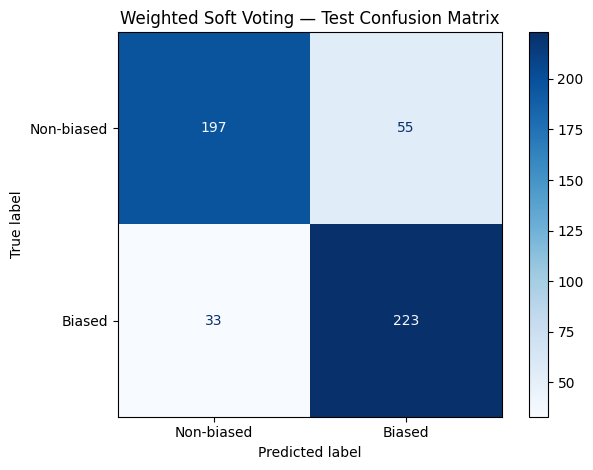

In [ ]:
selected_weights = best["weights"]
selected_threshold = float(best["threshold"])

p_test_ensemble = weighted_probability(test_prob, selected_weights)
pred_test_ensemble = (p_test_ensemble >= selected_threshold).astype(int)

# Individual models are evaluated on the same test examples at threshold 0.5.
final_rows = []
for name in MODEL_NAMES:
    p = np.asarray(test_prob[name])
    pred = (p >= 0.5).astype(int)
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro_precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro_recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro_F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Biased_precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Biased_recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "Biased_F1": f1_score(y_test, pred, pos_label=1, zero_division=0)
    })

final_rows.append({
    "Model": "Weighted Soft Voting",
    "Accuracy": accuracy_score(y_test, pred_test_ensemble),
    "Macro_precision": precision_score(y_test, pred_test_ensemble, average="macro", zero_division=0),
    "Macro_recall": recall_score(y_test, pred_test_ensemble, average="macro", zero_division=0),
    "Macro_F1": f1_score(y_test, pred_test_ensemble, average="macro", zero_division=0),
    "Biased_precision": precision_score(y_test, pred_test_ensemble, pos_label=1, zero_division=0),
    "Biased_recall": recall_score(y_test, pred_test_ensemble, pos_label=1, zero_division=0),
    "Biased_F1": f1_score(y_test, pred_test_ensemble, pos_label=1, zero_division=0)
})

final_metrics = pd.DataFrame(final_rows).sort_values("Macro_F1", ascending=False)
display(final_metrics.round(4))
final_metrics.to_csv(OUTPUT_DIR / "final_test_comparison.csv", index=False)

print("\nSelected weighted-soft-voting classification report:")
print(classification_report(
    y_test, pred_test_ensemble, labels=[0, 1],
    target_names=["Non-biased", "Biased"], digits=4, zero_division=0
))
cm = confusion_matrix(y_test, pred_test_ensemble, labels=[0, 1])
print("Confusion matrix (rows=true [Non-biased, Biased], columns=predicted):\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["Non-biased", "Biased"]).plot(cmap="Blues")
plt.title("Weighted Soft Voting — Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 9. Save final test predictions and calculate error rates

In [ ]:
test_out["ensemble_probability_biased"] = p_test_ensemble
test_out["ensemble_prediction"] = pred_test_ensemble
test_out["ensemble_correct"] = test_out["label"].to_numpy() == pred_test_ensemble
test_out.to_csv(OUTPUT_DIR / "weighted_soft_voting_test_predictions.csv", index=False)

tn, fp, fn, tp = confusion_matrix(y_test, pred_test_ensemble, labels=[0, 1]).ravel()
error_summary = pd.DataFrame([{
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan,
    "false_negative_rate": fn / (fn + tp) if fn + tp else np.nan,
    "specificity": tn / (tn + fp) if tn + fp else np.nan,
    "balanced_accuracy": (recall_score(y_test, pred_test_ensemble, pos_label=0, zero_division=0)
                          + recall_score(y_test, pred_test_ensemble, pos_label=1, zero_division=0)) / 2
}])
display(error_summary.round(4))
error_summary.to_csv(OUTPUT_DIR / "ensemble_error_analysis.csv", index=False)

print("All outputs saved under:", OUTPUT_DIR)


,TN,FP,FN,TP,false_positive_rate,false_negative_rate,specificity,balanced_accuracy
0,197,55,33,223,0.2183,0.1289,0.7817,0.8264


All outputs saved under: /content/drive/MyDrive/NewsBias_Project_Backup/weighted_soft_voting


## 10. Interpretation checklist

- Compare weighted soft voting against **each individual model evaluated on this same test split**.
- The ensemble is useful only if it improves the chosen objective or provides a justified trade-off, such as higher biased-class recall without unacceptable precision loss.
- Do not claim improvement if weighted soft voting does not beat the strongest individual model on your primary metric.
- Weights and threshold were selected on validation macro-F1. Do not tune them again based on test results.
- If any transformer checkpoint was trained using different splits, stop and retrain/use a checkpoint trained on the exact split before comparing.
- Save this notebook's output CSVs and selected config JSON with your project report.
